# Stage 4 (part 1) — Shared runner, linear models, tree ensembles

| Part | Prompt | Code |
|---|---|---|
| 1 | 4.1 shared experiment runner | `src/experiment.py`, `tests/test_experiment.py` |
| 2 | 4.2 linear family | `src/models.py` (`LINEAR_CLS`, `LINEAR_REG`) |
| 3 | 4.3 Random Forest, XGBoost, LightGBM, CatBoost | `src/models.py` (`trees`) |

Pre-registered metrics (Decision 3.7 / P1, approved): **classification** — BSS vs climatology (headline), PR-AUC,
ROC-AUC, CSI at a frozen threshold; **regression** — MAE (headline), MSESS, RMSE, wet-day MAE. Following P3 we also report
skill vs **seasonal + persistence** and folds 1–3 vs 4–5. Rule-11 triggers (P2): BSS > 0.45, monsoon ROC-AUC > 0.90,
MSESS > 0.60. Classification uses the primary target (≥ 1 mm); 0.1/2.5 mm follow for the final models.
The test set is not touched.

### Step 1 — Setup

**WHAT:** imports, paths, seeds; import the shared modules.

**WHY:** every model in this notebook goes through the same runner (rule 7), so all differences come from the models.

**Look for:** library versions (rule 13: APIs were checked against these versions).

In [1]:
import sys, subprocess, time, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import sklearn, xgboost, lightgbm, catboost
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.linear_model import LogisticRegression, lasso_path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import experiment as E, models as Mo, splits as S

FIG, TAB = ROOT / "reports/figures", ROOT / "reports/tables"
np.random.seed(0)
pd.set_option("display.width", 200, "display.max_columns", 40, "display.precision", 3)
def save(fig, name): fig.savefig(FIG / name, dpi=300, bbox_inches="tight")
print("sklearn", sklearn.__version__, "| xgboost", xgboost.__version__, "| lightgbm", lightgbm.__version__,
      "| catboost", catboost.__version__, "| seeds", Mo.SEEDS)

sklearn 1.9.1 | xgboost 3.4.1 | lightgbm 4.7.0 | catboost 1.2.10 | seeds [0, 1, 2, 3, 4]


**Interpretation:** versions recorded: scikit-learn 1.9.1, XGBoost 3.4.1, LightGBM 4.7.0, CatBoost 1.2.10; seeds 0–4.

**Decision:** versions pinned in `requirements.txt`.

**Paper note:** *Models were implemented with scikit-learn 1.9.1, XGBoost 3.4.1, LightGBM 4.7.0 and CatBoost 1.2.10.*

# Part 1 — Prompt 4.1: the shared runner

### Step 2 — Design of `run_cv` (and why)

For each of the 5 folds:

1. **Inner split.** The training fold is split into *inner-train* and a **"slice"** = its last 3 target years
   (e.g. fold 1: inner-train 1981–2001, slice 2002–2004), with the same 1-day purge.
2. **Inner fit → choices.** A copy of the model is fitted on inner-train and predicts the slice. From these
   out-of-sample predictions we take (a) the **decision threshold** that maximises CSI and (b) for gradient boosters the
   **number of trees** at which the slice loss stops improving (early stopping, patience 100).
3. **Refit.** A fresh model is fitted on the **whole training fold** (boosters with the number of trees from step 2), so the
   most recent years are used for learning, then it predicts the validation block.
4. **Score & store.** Validation predictions are scored with `src/metrics.py`; skill references (climatology,
   seasonal + persistence) are the Stage-3 baselines fitted on the same training fold. Out-of-fold (OOF) predictions →
   `models/oof/<model>__<task>__<set>__seed<k>.parquet`; tidy rows `(model, task, feature_set, fold, seed, metric, value)` →
   `reports/tables/cv_results.csv`. Re-running a configuration **replaces** its old rows (no duplicates).

**Design choices and alternatives**

| choice | why | alternative considered |
|---|---|---|
| threshold & early stopping on the last 3 training years | out-of-sample for the inner model, never touches the validation block (your Stage-3 answer 3); most recent years resemble the validation period best | (a) the validation block itself → optimistic, peeks at labels; (b) in-sample training rows → over-confident ML probabilities; (c) earlier folds' OOF → fold 1 would have none |
| refit on the full training fold | keeps the newest 3 years for learning (important with the regime shifts) | keep the inner model → loses the most relevant data |
| keep the inner number of trees unchanged at refit | simple, common practice; the full fold is only ~12–25 % larger | scale trees by data size → an extra assumption |
| Pipelines (one-hot month + StandardScaler) for linear models | rule 6: preprocessing fitted on training rows only | scaling the whole table once → leaks validation means/stds |
| raw features for trees | splits are invariant to monotone rescaling | — |
| deterministic models 1 seed, stochastic 5 seeds | rule 8; repeating a deterministic fit gives identical numbers | 5 seeds for all → wasted compute |
| regression trained on mm (`y_reg`), predictions clipped at 0 | MAE/RMSE are evaluated in mm; negative rain is impossible | `y_reg_log` (Jensen bias, Stage 2 Q3) → part 2 |
| `class_weight="balanced"` | requested; with ~49 % rain days it changes weights by only ~±5 % | none — note it can distort probabilities when classes are imbalanced |

**Approximation to keep in mind:** the threshold is chosen for the inner model and applied to the refitted model; their
probabilities are very similar but not identical.

**Look for (next step):** all runner tests pass.

In [2]:
r = subprocess.run([sys.executable, "-m", "pytest", "-q", "--color=no", "-p", "no:cacheprovider", str(ROOT / "tests")],
                   capture_output=True, text=True, cwd=ROOT)
print(r.stdout[-600:], r.stderr[-300:])

................................................                         [100%]
48 passed in 3.15s
 


**Interpretation:** all 48 project tests pass (leakage, splits, metrics and the 6 new runner tests). The runner tests use a
"spy" estimator that records the rows of every fit; they prove that (i) every fit uses only rows whose targets precede the
validation block, (ii) the final model sees exactly the training fold, (iii) the threshold slice lies inside the training
fold, (iv) OOF predictions cover exactly the validation blocks, (v) re-runs do not duplicate rows.

**Decision:** the runner is trusted for all models.

**Paper note:** *The cross-validation runner was verified with automated tests showing that neither model fitting nor
threshold selection used validation-period observations.*

### Step 3 — Plumbing check with trivial models, and baseline rows in the same table

**WHAT:** (i) write the Stage-3 baselines into `cv_results.csv` with exactly the same metric code (`baseline:<name>`,
feature set "-"); (ii) run a trivial model through the runner: `DummyClassifier(strategy="prior")` (predicts the training
base rate) and `DummyRegressor()` (training mean), on Set A.

**WHY:** a trivial model has known answers: ROC-AUC = 0.5, and its scores must equal the majority/mean baseline exactly,
because it *is* the same forecast computed through a different code path. Agreement proves the runner's splits, metric
calls and storage are wired correctly.

**Alternatives considered:** going straight to a real model — a plumbing error would then be indistinguishable from a
modelling result.

**Look for:** dummy = majority on every fold (difference 0), ROC-AUC 0.5.

In [3]:
for task in ("cls", "reg"):
    E.run_baselines(task)
dummy = {"cls": lambda s, y: DummyClassifier(strategy="prior"), "reg": lambda s, y: DummyRegressor()}
check = {}
for task, metric in (("cls", "BSS"), ("reg", "MAE")):
    res_d, oof_d, log_d = E.run_cv("dummy", dummy[task], task, "A")
    cv = pd.read_csv(E.RESULTS)
    base = cv[(cv.model == "baseline:majority") & (cv.task == task) & (cv.metric == metric)].sort_values("fold")["value"].to_numpy()
    mine = res_d[res_d.metric == metric].sort_values("fold")["value"].to_numpy()
    check[f"{task}: {metric} dummy - majority (max abs diff)"] = np.abs(mine - base).max()
check["cls: dummy ROC-AUC (all folds)"] = pd.read_csv(E.RESULTS).query("model=='dummy' and task=='cls' and metric=='ROC_AUC'")["value"].unique()
pd.Series(check, dtype=object).to_frame("value")

,value
cls: BSS dummy - majority (max abs diff),0.0
reg: MAE dummy - majority (max abs diff),0.0
cls: dummy ROC-AUC (all folds),[0.5]


**Interpretation:** the trivial models reproduce the Stage-3 majority/mean baseline **exactly** (max difference 0.0 for BSS and
MAE in every fold) and have ROC-AUC 0.5 in every fold. Two independent code paths give identical numbers → splits, metric
calls and storage are wired correctly.

**Decision:** baselines are now stored in `cv_results.csv` next to the models (`baseline:*`).

**Paper note:** *As a plumbing check, a constant forecast evaluated through the experiment runner reproduced the
majority/mean reference scores exactly.*

### Step 4 — Sanity check of one fold: the fold log and the out-of-fold predictions

**WHAT:** show the inner split / threshold log of the dummy classifier, and the first OOF rows of fold 5.

**WHY:** to see with our own eyes that the slice lies inside the training fold, the threshold was chosen there, and the
stored predictions belong to the validation days.

**Look for:** slices ending in 2004, 2007, …, 2016; OOF index starting 2016-12-31 (target 2017-01-01) for fold 5.

In [4]:
_, oof_d, log_d = E.run_cv("dummy", dummy["cls"], "cls", "A", save=False)
display(log_d)
oof_d[oof_d.fold == 5].head()

,fold,inner_train_last_target,slice_targets
0,1,2001-12-30,2002-01-01..2004-12-30
1,2,2004-12-30,2005-01-01..2007-12-30
2,3,2007-12-30,2008-01-01..2010-12-30
3,4,2010-12-30,2011-01-01..2013-12-30
4,5,2013-12-30,2014-01-01..2016-12-30


,fold,y_true,pred,threshold
date,,,,
2016-12-31,5,0,0.487,0.01
2017-01-01,5,0,0.487,0.01
2017-01-02,5,0,0.487,0.01
2017-01-03,5,0,0.487,0.01
2017-01-04,5,0,0.487,0.01


**Interpretation:** the slices are 2002–2004, 2005–2007, 2008–2010, 2011–2013 and 2014–2016: always the last 3 years
**inside** the training fold (ending 12-30 because of the purge), never in the validation block. The fold-5 OOF rows start on
2016-12-31 (target 2017-01-01). The dummy's threshold is 0.01, because a constant probability can only predict "always
rain" or "never rain" and CSI prefers "always rain" — a reminder that CSI rewards over-forecasting when nothing better
exists.

**Decision:** design confirmed.

**Paper note:** *Decision thresholds were selected by maximising CSI on the last three years of each training fold.*

# Part 2 — Prompt 4.2: the linear family

### Step 5 — Models

| task | model | penalty (scikit-learn 1.9 API) | solver | seeds |
|---|---|---|---|---|
| cls | `logreg_none` | none (`C=inf`) | lbfgs | 1 |
| cls | `logreg_l2` | L2, `C=1` (`l1_ratio=0`) | lbfgs | 1 |
| cls | `logreg_l1` | L1, `C=0.1` (`l1_ratio=1`) | saga (stochastic) | 5 |
| cls | `logreg_enet` | elastic net, `C=0.1`, `l1_ratio=0.5` | saga | 5 |
| cls | `sgd_logloss` | L2, `alpha=1e-4`, log loss | SGD | 5 |
| reg | `linreg` | none | least squares | 1 |
| reg | `ridge` | L2, `alpha=1` | closed form | 1 |
| reg | `lasso` | L1, `alpha=0.1` | coordinate descent | 1 |
| reg | `elasticnet` | `alpha=0.1`, `l1_ratio=0.5` | coordinate descent | 1 |
| reg | `sgd_reg` | L2, `alpha=1e-4`, squared loss | SGD | 5 |

All classifiers use `class_weight="balanced"`. All inputs: one-hot month (drop first) + standardised features inside the
Pipeline. **Not tuned.** The only non-default values are `C=0.1` for the L1/elastic-net logistic models and
`alpha=0.1` for Lasso/ElasticNet, chosen *a priori* (not by looking at scores) so that the sparsity is visible; with the
defaults (`C=1`, `alpha=1`) L1 logistic keeps almost all features and Lasso keeps very few at this rainfall scale (mm).

**Rule 13 note:** in scikit-learn 1.9 `LogisticRegression(penalty=...)` is deprecated; the penalty is set by `C` and
`l1_ratio` (verified on the installed version).

**Look for:** — (definitions)

### Step 6 — Run all linear models (Sets A and B)

**WHAT:** every model × feature set × seed through `run_cv`. One printed line per configuration.

**WHY:** identical folds, thresholds procedure, metrics and storage for all (rule 7).

**Look for:** no warnings about non-convergence; run times.

In [5]:
def run_family(specs, task, fsets=("A", "B")):
    for fset in fsets:
        for name, (factory, stochastic) in specs.items():
            for seed in (Mo.SEEDS if stochastic else [0]):
                t0 = time.time()
                with warnings.catch_warnings(record=True) as w:
                    warnings.simplefilter("always")
                    res_k, _, _ = E.run_cv(name, factory, task, fset, seed)
                head = res_k[res_k.metric == ("BSS" if task == "cls" else "MAE")]["value"].mean()
                print(f"{task} {fset} {name:13s} seed {seed}: {'BSS' if task == 'cls' else 'MAE'} {head:.3f} "
                      f"({time.time() - t0:5.1f}s){'  WARN: ' + str({x.category.__name__ for x in w}) if w else ''}")

run_family(Mo.LINEAR_CLS, "cls")
run_family(Mo.LINEAR_REG, "reg")

cls A logreg_none   seed 0: BSS 0.236 ( 55.7s)


cls A logreg_l2     seed 0: BSS 0.241 ( 30.6s)


cls A logreg_l1     seed 0: BSS 0.247 (  6.2s)


cls A logreg_l1     seed 1: BSS 0.247 (  6.1s)


cls A logreg_l1     seed 2: BSS 0.247 (  6.1s)


...

reg B sgd_reg       seed 0: MAE 7.367 (  1.1s)


reg B sgd_reg       seed 1: MAE 7.494 (  1.2s)


reg B sgd_reg       seed 2: MAE 7.395 (  1.2s)


reg B sgd_reg       seed 3: MAE 7.507 (  1.3s)


reg B sgd_reg       seed 4: MAE 7.472 (  1.2s)


**Interpretation:**
- **L1 / elastic-net logistic regression gives identical scores for all 5 seeds** (BSS 0.247 / 0.253). The problem is convex
  and saga converged, so the random data order does not change the optimum — the seed only matters if the solver stops
  early. SGD is different: it is stopped after a fixed budget, so seeds give BSS between 0.159 and 0.238 (Set B) — a
  sign of an under-converged, noisy optimiser with default settings.
- Regression runs take ~1 s each; `logreg_none` (C = ∞) is the slowest (85 s for Set B) because an unpenalised fit on
  125 correlated columns converges slowly.
- No convergence warnings were raised in any CV run.

**Decision:** SGD is reported but is not a candidate for the final comparison without tuning its learning rate/iterations.

**Paper note:** *For convex models solved to convergence, results were invariant to the random seed, whereas stochastic
gradient descent with default settings showed substantial seed-to-seed variability.*

### Step 7 — Linear models vs baselines (mean ± fold std; folds 1–3 vs 4–5; seed std)

**WHAT:** the pre-registered metrics for every linear model and the main baselines. `mean ± std` = mean over the 5 folds
(seed-averaged) ± std across folds; `folds 1–3` / `folds 4–5` = means before / across the 2016 jump; `seed std` = std of the
5-fold mean across seeds (0 for deterministic models).

**WHY:** P1 and P3. The skill vs seasonal + persistence column answers "did the model learn anything beyond season and
persistence?"

**Look for:** BSS above 0.184 and BSS_vs_seas_pers > 0; regression MAE below 7.08 and MSESS_vs_seas_pers > 0; whether gains
come from folds 4–5 only.

In [6]:
CLS_KEY = ["BSS", "BSS_vs_seas_pers", "PR_AUC", "ROC_AUC", "ROC_AUC_monsoon", "CSI", "ECE"]
REG_KEY = ["MAE", "MSESS", "MSESS_vs_seas_pers", "RMSE", "MAE_wet", "bias", "recall_ge20"]
BASE = ["baseline:seasonal+persistence", "baseline:climatology", "baseline:persistence"]

def compare(task, models, keys, headline, name):
    cv = pd.read_csv(E.RESULTS)
    s = E.summarise(cv[(cv.task == task) & cv.model.isin(models)], keys)
    s["cell"] = s["mean"].map("{:.3f}".format) + " ± " + s["fold_std"].map("{:.3f}".format)
    wide = s.pivot_table(index=["model", "feature_set"], columns="metric", values="cell", aggfunc="first")[keys]
    h = s[s.metric == headline].set_index(["model", "feature_set"])
    wide[f"{headline} folds 1-3"] = h["folds_1_3"].round(3)
    wide[f"{headline} folds 4-5"] = h["folds_4_5"].round(3)
    wide[f"{headline} seed std"] = h["seed_std"].fillna(0).round(4)
    order = h["mean"].sort_values(ascending=(headline == "MAE")).index
    wide = wide.loc[order]
    wide.to_csv(TAB / f"{name}.csv")
    return wide

display(compare("cls", BASE + list(Mo.LINEAR_CLS), CLS_KEY, "BSS", "04_linear_vs_baselines_cls"))
compare("reg", BASE + list(Mo.LINEAR_REG), REG_KEY, "MAE", "04_linear_vs_baselines_reg")

,metric,BSS,BSS_vs_seas_pers,PR_AUC,ROC_AUC,ROC_AUC_monsoon,CSI,ECE,BSS folds 1-3,BSS folds 4-5,BSS seed std
model,feature_set,,,,,,,,,,
logreg_l1,B,0.253 ± 0.051,0.084 ± 0.009,0.954 ± 0.015,0.955 ± 0.009,0.799 ± 0.031,0.817 ± 0.017,0.030 ± 0.006,0.226,0.293,0.000
logreg_enet,B,0.252 ± 0.049,0.083 ± 0.008,0.954 ± 0.015,0.955 ± 0.009,0.794 ± 0.032,0.815 ± 0.021,0.034 ± 0.005,0.226,0.291,0.000
logreg_l2,B,0.249 ± 0.050,0.079 ± 0.014,0.953 ± 0.015,0.954 ± 0.010,0.793 ± 0.032,0.816 ± 0.022,0.028 ± 0.007,0.220,0.291,0.000
logreg_l1,A,0.247 ± 0.054,0.077 ± 0.012,0.954 ± 0.016,0.954 ± 0.010,0.802 ± 0.035,0.821 ± 0.029,0.033 ± 0.008,0.217,0.292,0.000
logreg_enet,A,0.247 ± 0.053,0.077 ± 0.012,0.953 ± 0.016,0.954 ± 0.010,0.801 ± 0.034,0.820 ± 0.029,0.032 ± 0.009,0.217,0.291,0.000
logreg_none,B,0.243 ± 0.054,0.073 ± 0.017,0.952 ± 0.016,0.953 ± 0.010,0.789 ± 0.032,0.822 ± 0.030,0.029 ± 0.007,0.212,0.290,0.000
logreg_l2,A,0.241 ± 0.052,0.070 ± 0.015,0.953 ± 0.016,0.953 ± 0.010,0.802 ± 0.037,0.821 ± 0.028,0.031 ± 0.008,0.211,0.287,0.000
logreg_none,A,0.236 ± 0.054,0.064 ± 0.017,0.952 ± 0.017,0.953 ± 0.010,0.797 ± 0.039,0.813 ± 0.025,0.032 ± 0.006,0.204,0.285,0.000
sgd_logloss,A,0.193 ± 0.041,0.010 ± 0.032,0.946 ± 0.017,0.948 ± 0.011,0.788 ± 0.042,0.803 ± 0.029,0.035 ± 0.005,0.170,0.227,0.019


metric                                               MAE           MSESS MSESS_vs_seas_pers            RMSE         MAE_wet            bias    recall_ge20  MAE folds 1-3  MAE folds 4-5  MAE seed std
model                         feature_set                                                                                                                                                             
baseline:seasonal+persistence -            7.079 ± 1.676   0.228 ± 0.106      0.000 ± 0.000  14.008 ± 3.956  11.827 ± 2.389  -2.124 ± 1.789  0.321 ± 0.132          6.167          8.446         0.000
lasso                         A            7.292 ± 1.869   0.208 ± 0.061     -0.033 ± 0.068  14.316 ± 4.519  12.028 ± 2.628  -2.106 ± 2.157  0.333 ± 0.129          6.259          8.841         0.000
                              B            7.305 ± 1.881   0.208 ± 0.061     -0.033 ± 0.067  14.317 ± 4.513  12.027 ± 2.622  -2.087 ± 2.127  0.334 ± 0.133          6.258          8.875         0.000
elasticnet                    A            7.364 ± 1.910   0.202 ± 0.056     -0.041 ± 0.074  14.381 ± 4.567  12.045 ± 2.714  -2.064 ± 2.163  0.310 ± 0.125          6.304          8.953         0.000
                              B            7.365 ± 1.911   0.202 ± 0.057     -0.041 ± 0.073  14.382 ± 4.564  12.044 ± 2.714  -2.059 ± 2.157  0.312 ± 0.130          6.304          8.957         0.000
ridge                         B            7.402 ± 1.672   0.226 ± 0.076     -0.007 ± 0.044  14.112 ± 4.296  12.024 ± 2.417  -1.404 ± 2.102  0.405 ± 0.145          6.504          8.749         0.000
linreg                        B            7.412 ± 1.668   0.226 ± 0.076     -0.007 ± 0.043  14.113 ± 4.293  12.028 ± 2.415  -1.387 ± 2.105  0.404 ± 0.146          6.519          8.751         0.000
                              A            7.413 ± 1.738   0.221 ± 0.071     -0.014 ± 0.050  14.169 ± 4.359  12.003 ± 2.472  -1.607 ± 2.071  0.385 ± 0.144          6.456          8.849         0.000
ridge                         A            7.414 ± 1.746   0.221 ± 0.071     -0.014 ± 0.050  14.167 ± 4.357  12.001 ± 2.472  -1.602 ± 2.055  0.384 ± 0.144          6.447          8.863         0.000
sgd_reg                       B            7.447 ± 1.584   0.220 ± 0.088     -0.013 ± 0.026  14.128 ± 4.136  12.054 ± 2.397  -1.371 ± 1.858  0.406 ± 0.182          6.582          8.744         0.062
                              A            7.456 ± 1.710   0.215 ± 0.076     -0.021 ± 0.045  14.211 ± 4.334  12.063 ± 2.476  -1.582 ± 2.056  0.387 ± 0.153          6.508          8.879         0.043
baseline:persistence          -            7.904 ± 1.618  -0.037 ± 0.254     -0.326 ± 0.150  15.959 ± 3.763  14.134 ± 1.821  -0.000 ± 0.000  0.509 ± 0.148          7.116          9.086         0.000
baseline:climatology          -            8.100 ± 2.464   0.000 ± 0.000     -0.315 ± 0.182  16.233 ± 5.654  13.311 ± 3.935  -3.693 ± 3.202  0.000 ± 0.000          6.698         10.204         0.000

**Interpretation — classification (≥ 1 mm):**
- Regularised logistic regression clearly beats the reference: `logreg_l1` (Set B) BSS **0.253 ± 0.051** vs 0.184 for
  seasonal + persistence; BSS vs seasonal + persistence **0.084 ± 0.009** — positive in every fold, with a very small spread.
  Monsoon ROC-AUC 0.80 vs 0.73; PR-AUC 0.954 vs 0.932. CSI improves only slightly (0.817 vs 0.813): most of the gain is in
  **probability quality**, not in the yes/no decision.
- Calibration is good (ECE ≈ 0.03) despite `class_weight="balanced"` — expected, since classes are ~50/50.
- Regularisation helps a little (none 0.243 → L2 0.249 → L1 0.253); Set B helps a little (+0.006 in all 5 folds for L1).
- BSS is higher in folds 4–5 (0.29) than 1–3 (0.23), but BSS vs seasonal + persistence is stable — much of the post-2016
  "gain" is the climatology reference getting worse (Stage 3).

**Interpretation — regression (mm):** **no linear model beats seasonal + persistence**: MAE 7.29–7.46 vs 7.08, MSESS vs
seasonal + persistence ≤ 0. Lasso has the best MAE among them (7.29) but a worse RMSE than Ridge. All are biased low
(−1.4 to −2.1 mm/day).

**Decision:** linear classification is a strong, interpretable benchmark (logreg_l1, Set B); linear regression on raw mm is
not competitive — see "Why linear models struggle".

**Paper note:** *L1-regularised logistic regression improved the Brier skill score from 0.18 (seasonal-persistence reference)
to 0.25 ± 0.05, with a consistent gain of 0.08 ± 0.01 over the reference in every fold, whereas linear regression of
rainfall amounts did not outperform the reference (MAE 7.3 vs 7.1 mm day⁻¹).*

### Step 8 — Rule-11 check

**WHAT:** list any fold of any model where BSS > 0.45, monsoon ROC-AUC > 0.90 or MSESS > 0.60 (approved triggers, P2).

**WHY:** suspiciously good scores must be investigated before they are reported.

**Look for:** an empty table.

In [7]:
def rule11():
    cv = pd.read_csv(E.RESULTS)
    trig = {"BSS": 0.45, "ROC_AUC_monsoon": 0.90, "MSESS": 0.60}
    hits = cv[cv.metric.isin(trig) & (cv.value > cv.metric.map(trig))]
    print(f"configurations checked: {cv.groupby(E.KEYS).ngroups}; fold-level trigger hits: {len(hits)}")
    print("max per metric:", cv[cv.metric.isin(trig)].groupby("metric")["value"].max().round(3).to_dict())
    return hits
rule11()

configurations checked: 64; fold-level trigger hits: 0
max per metric: {'BSS': 0.302, 'MSESS': 0.346, 'ROC_AUC_monsoon': 0.874}


,model,task,feature_set,fold,seed,metric,value


**Interpretation:** no fold of any linear model triggers rule 11 (max BSS 0.302, max monsoon ROC-AUC 0.874, max MSESS 0.346).

**Decision:** no investigation needed.

**Paper note:** *No model exceeded the pre-specified plausibility thresholds for skill.*

### Step 9 — Sanity look at predictions: fold 5, one wet season

**WHAT:** observed rain and the out-of-fold predictions of `logreg_l2` (probability) and `ridge` (mm) for March–October
2018 (Set B), next to the seasonal + persistence baseline.

**WHY:** numbers can hide silly behaviour (e.g. a constant forecast, a one-day shift). Eyeballing a season checks that
probabilities rise before and during rain and that mm forecasts are plausible.

**Look for:** probabilities near 1 in the monsoon and dropping in dry breaks; regression forecasts much smoother than
observations (they cannot forecast 100-mm days).

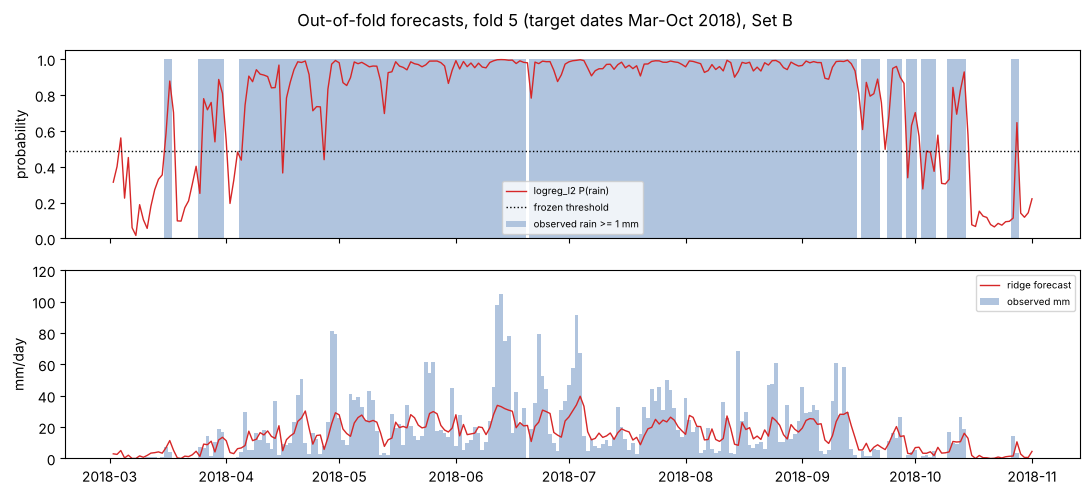

In [8]:
o_c = pd.read_parquet(E.OOF_DIR / "logreg_l2__cls__B__seed0.parquet")
o_r = pd.read_parquet(E.OOF_DIR / "ridge__reg__B__seed0.parquet")
win = slice("2018-03-01", "2018-10-31")
t = S.target_dates(o_c.loc[win].index)
fig, (a0, a1) = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
a0.bar(t, o_c.loc[win, "y_true"], color="lightsteelblue", width=1, label="observed rain >= 1 mm")
a0.plot(t, o_c.loc[win, "pred"], color="tab:red", lw=1, label="logreg_l2 P(rain)")
a0.axhline(o_c.loc[win, "threshold"].iloc[0], color="k", ls=":", lw=1, label="frozen threshold")
a0.legend(fontsize=7, loc="lower center"); a0.set_ylabel("probability")
a1.bar(t, o_r.loc[win, "y_true"], color="lightsteelblue", width=1, label="observed mm")
a1.plot(t, o_r.loc[win, "pred"], color="tab:red", lw=1, label="ridge forecast")
a1.set(ylabel="mm/day", ylim=(0, 120)); a1.legend(fontsize=7)
fig.suptitle("Out-of-fold forecasts, fold 5 (target dates Mar-Oct 2018), Set B"); fig.tight_layout()
save(fig, "04_oof_sanity_fold5.png"); plt.show()

**Interpretation:** the forecasts behave sensibly. The rain probability rises with the pre-monsoon showers (late March–
April), stays near 1 through the monsoon, dips at short dry breaks, and falls during the retreat (mid-September–October); it
reacts one day *after* changes, as expected from persistence-driven inputs. The ridge forecast is a smooth 10–35 mm/day
curve while observed rain reaches 105 mm: the model **cannot forecast extremes and over-forecasts light days** — the typical
behaviour of a conditional-mean regression on a skewed target.

**Decision:** no plumbing problems; regression needs a different target/loss (part 2).

**Paper note:** *Out-of-fold rain probabilities tracked the seasonal transitions and intraseasonal dry spells, whereas
regression forecasts were strongly smoothed and did not reproduce heavy-rainfall days.*

### Step 10 — What the coefficients say: top standardised coefficients

**WHAT:** fit `logreg_l2` and `ridge` on all development rows (targets 1981–2019; no test data), Set B, and plot the 15
largest standardised coefficients (change in log-odds or mm per 1-std change of the feature, holding the others fixed).

**WHY:** linear models are interpretable — but only *conditionally*: with many correlated features (QV2M, T2MDEW, their lags
and means) coefficients share credit and can even flip sign. Read them as "what the model uses", not as causal effects.

**Alternatives considered:** permutation importance (model-agnostic) — will be used for all models in a later stage.

**Look for:** whether the dominant terms are rain persistence, moisture, pressure tendency and season, and any
counter-intuitive signs that reveal collinearity.

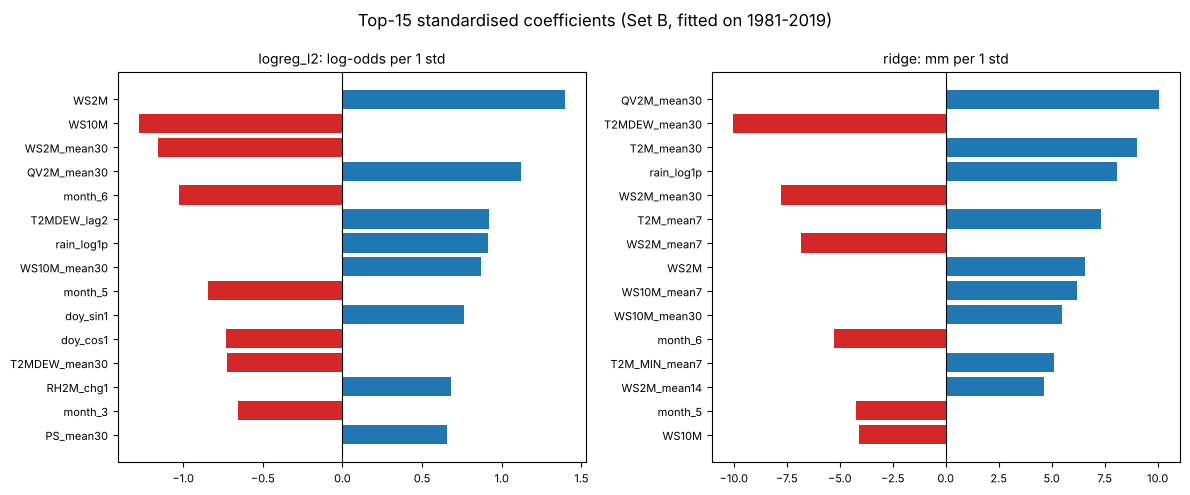

In [9]:
X, Y = E.load("B"); dev = S.dev_index(X.index)
def fitted_coefs(factory, target):
    pipe = factory(0, Y.loc[dev, target]).fit(X.loc[dev], Y.loc[dev, target])
    names = [n.split("__", 1)[1] for n in pipe[0].get_feature_names_out()]
    return pd.Series(np.ravel(pipe[-1].coef_), index=names), pipe

coef_c, _ = fitted_coefs(Mo.LINEAR_CLS["logreg_l2"][0], "y_cls")
coef_r, pipe_r = fitted_coefs(Mo.LINEAR_REG["ridge"][0], "y_reg")
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, c, title in ((axes[0], coef_c, "logreg_l2: log-odds per 1 std"), (axes[1], coef_r, "ridge: mm per 1 std")):
    top = c.reindex(c.abs().sort_values(ascending=False).index[:15])[::-1]
    ax.barh(top.index, top, color=np.where(top > 0, "tab:blue", "tab:red")); ax.axvline(0, color="k", lw=0.8)
    ax.set_title(title, fontsize=10); ax.tick_params(labelsize=8)
fig.suptitle("Top-15 standardised coefficients (Set B, fitted on 1981-2019)"); fig.tight_layout()
save(fig, "04_linear_top_coefficients.png"); plt.show()
pd.DataFrame({"logreg_l2": coef_c, "ridge": coef_r}).round(4).to_csv(TAB / "04_linear_coefficients_setB.csv")

**Interpretation:**
- **Collinearity is visible immediately.** Ridge gives `QV2M_mean30` **+10.0 mm** and `T2MDEW_mean30` **−10.1 mm**: two
  measures of the same moisture with huge opposite coefficients that almost cancel. Logistic regression gives `WS2M` +1.40 and
  `WS10M` −1.29: the model uses the *difference* between 2-m and 10-m wind (a near-surface stability/roughness proxy) rather
  than wind speed itself. Such coefficients cannot be read one at a time.
- Interpretable terms with physically sensible signs: **rain today** (`rain_log1p`, + in both), **moist regime**
  (`QV2M_mean30` +), **moistening** (`RH2M_chg1` +), **dew point two days ago** (`T2MDEW_lag2` +).
- Month dummies (relative to January) are negative although rain is more likely in May–June: they only *correct* the
  sin/cos harmonics, which already carry the seasonal cycle. Again, conditional on everything else.

**Decision:** we will not interpret individual linear coefficients in the paper; we will use grouped/permutation importance
for all models (later stage), and the Lasso paths below for "which information enters first".

**Paper note:** *Standardised coefficients of the linear models were strongly affected by collinearity among moisture and
wind predictors and were therefore not interpreted individually.*

### Step 11 — Coefficient paths and the features Lasso / L1-logistic keep

**WHAT:** (a) the Lasso path for regression (`lasso_path`, standardised inputs, 40 penalties); (b) the L1-logistic path
(8 values of C). (c) The features with non-zero coefficients at the penalties used in Step 6 (Lasso α = 0.1, L1-logistic
C = 0.1), fitted on the development rows.

**WHY:** a path shows the *order* in which features enter as the penalty is relaxed — the earliest ones carry the most
unique information. The selected set shows how much of the 115-feature table a linear model really needs.

**Alternatives considered:** stability selection (refit on bootstrap samples) — more robust, more compute; later if needed.

**Look for:** the first ~5 features to enter, and how many features survive.

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:827: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.060512e+03, tolerance: 3.140e+02
  model = cd_fast.enet_coordinate_descent_gram(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:827: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 8.121176e+03, tolerance: 3.140e+02
  model = cd_fast.enet_coordinate_descent_gram(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:827: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.226408e+04

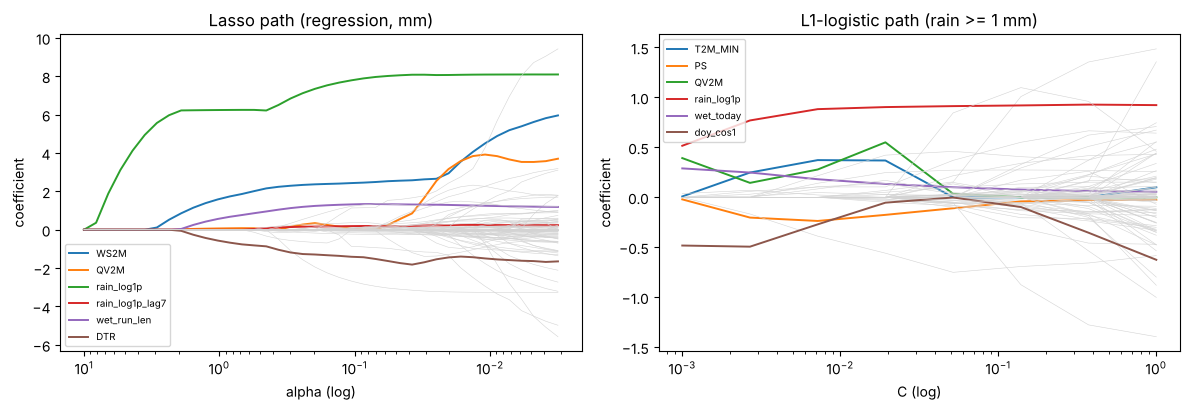

{'lasso (alpha=0.1)': '23 of 125 features kept', 'logreg_l1 (C=0.1)': '42 of 125 features kept'}
first 10 to enter - Lasso: ['rain_log1p', 'WS2M', 'QV2M', 'wet_run_len', 'DTR', 'rain_log1p_lag7', 'WS10M_mean30', 'QV2M_chg1', 'PS_chg1', 'doy_cos1']
first 10 to enter - L1-logistic: ['T2M_MIN', 'wet_today', 'QV2M', 'PS', 'rain_log1p', 'doy_cos1', 'rain_sum3_log1p', 'rain_sum7_log1p', 'RH2M_chg1', 'DTR']


In [10]:
pre = Mo.linear_pre().fit(X.loc[dev])
names = [n.split("__", 1)[1] for n in pre.get_feature_names_out()]
Z = pre.transform(X.loc[dev]); Zc = Z - Z.mean(0)
yr = Y.loc[dev, "y_reg"].to_numpy(); yc = Y.loc[dev, "y_cls"].to_numpy()
alphas, path_r, _ = lasso_path(Zc, yr - yr.mean(), alphas=np.logspace(1, -2.5, 40))
Cs = np.logspace(-3, 0, 8)
path_c = np.array([LogisticRegression(C=C, l1_ratio=1.0, solver="saga", max_iter=5000, random_state=0)
                   .fit(Z, yc).coef_.ravel() for C in Cs]).T

def entry_order(path):           # index of the first penalty at which each feature becomes non-zero
    nz = np.abs(path) > 1e-8
    return pd.Series(np.where(nz.any(1), nz.argmax(1), np.inf), index=names).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, path, x, lab, title in ((axes[0], path_r, alphas, "alpha (log)", "Lasso path (regression, mm)"),
                                (axes[1], path_c, Cs, "C (log)", "L1-logistic path (rain >= 1 mm)")):
    first = entry_order(path).index[:6]
    for i, n in enumerate(names):
        ax.plot(x, path[i], lw=1.4 if n in first else 0.4, color=None if n in first else "lightgrey",
                label=n if n in first else None)
    ax.set_xscale("log"); ax.set(xlabel=lab, ylabel="coefficient", title=title); ax.legend(fontsize=7)
axes[0].invert_xaxis()
fig.tight_layout(); save(fig, "04_linear_coefficient_paths.png"); plt.show()

lasso_fit = Mo.LINEAR_REG["lasso"][0](0, None).fit(X.loc[dev], yr)
l1_fit = Mo.LINEAR_CLS["logreg_l1"][0](0, None).fit(X.loc[dev], yc)
sel = {m: pd.Series(np.ravel(p[-1].coef_), index=names) for m, p in (("lasso (alpha=0.1)", lasso_fit), ("logreg_l1 (C=0.1)", l1_fit))}
sel_tab = pd.DataFrame(sel)
sel_tab[(sel_tab.abs() > 1e-8).any(axis=1)].round(4).to_csv(TAB / "04_l1_selected_features_setB.csv")
print({m: f"{(s.abs() > 1e-8).sum()} of {len(s)} features kept" for m, s in sel.items()})
print("first 10 to enter - Lasso:", list(entry_order(path_r).index[:10]))
print("first 10 to enter - L1-logistic:", list(entry_order(path_c).index[:10]))

**Interpretation:**
- **Lasso (regression):** the first feature by far is **today's rain** (`rain_log1p`, enters at α ≈ 10 and dominates), then
  2-m wind speed, specific humidity, current wet-spell length, **DTR (negative: a large day–night temperature range means clear
  skies)**, rain 7 days ago, 30-day mean 10-m wind, 1-day QV2M change, 1-day pressure change and the seasonal cosine.
- **L1-logistic (classification):** minimum temperature, rain-today flag, specific humidity, surface pressure, rain today,
  seasonal cosine, 3- and 7-day rain sums, RH change and DTR.
- At the penalties used in the CV, Lasso keeps **23 of 125** columns and L1-logistic **42 of 125** — and they are the best linear
  models in MAE and BSS respectively. Most of the 115 features are redundant for a linear model.
- The same story as Stage 1: **persistence, moisture, moistening, cloudiness (DTR/T2M_MIN), pressure and season.**
- Caveat: `lasso_path` (default 1,000 iterations) did not fully converge at the smallest α values; the right-hand end of the
  left panel is approximate. The CV Lasso models (20,000 iterations) converged.

**Decision:** keep all features for now (rule 7: identical features for every model); the selected subset is reported as an
interpretation result, not used to filter features.

**Paper note:** *L1 regularisation retained 23 (regression) and 42 (classification) of 125 predictor columns; the first
predictors selected were same-day rainfall, near-surface humidity, wind speed and the diurnal temperature range.*

### Why linear models struggle with rainfall — and what the coefficients say physically

1. **The target is zero-inflated and heavy-tailed.** A squared-error linear model predicts the conditional *mean*, which on a
   dry-season day is a small positive number (never 0) and on a storm day is far below the observed 100 mm. Clipping negatives
   at 0 fixes the sign, not the shape. This is why linear **regression** fails to beat the reference.
2. **The physics is non-linear and threshold-like.** Rain needs near-saturation and a trigger: humidity rising from 60 % to 70 %
   changes little, from 90 % to 98 % a lot. Additive straight lines cannot represent saturation or triggers.
3. **Relationships change with the season.** Pressure matters in the pre-monsoon but hardly in the monsoon (Stage 1); a single
   linear coefficient averages these, unless we add season × feature interactions by hand.
4. **Collinearity** makes individual coefficients unstable (QV2M vs T2MDEW, WS2M vs WS10M).
5. **Why classification still works well:** the logistic link turns additive effects into a probability that saturates at 0 and 1,
   and the log-odds of rain *is* roughly additive in persistence + moisture + season. Hence logistic regression reaches
   BSS 0.25 — close to the boosters.

**Physically**, the linear models agree on the main drivers of next-day rain at Sylhet: **today's rain and the length of the wet
spell (persistence), the amount of moisture (QV2M, dew point, their 30-day means), moistening (RH and QV2M increasing),
cloudiness (small DTR, warm nights) and the seasonal cycle**, with wind speed (monsoon flow) and pressure tendency as secondary
signals.

**Paper note:** *The limited skill of linear regression for rainfall amounts reflects the zero-inflated, heavy-tailed target
distribution and the non-linear, season-dependent controls on rainfall, whereas rain occurrence was well described by an
additive log-odds model of persistence, moisture and seasonality.*

# Part 3 — Prompt 4.3: tree ensembles and gradient boosting

### Step 12 — Bagging vs boosting, scaling, and the hyper-parameters we use

**Bagging (Random Forest).** Many deep trees, each grown on a bootstrap sample of the rows and a random subset of
features at each split; predictions are averaged. Averaging many *different*, individually over-fitted trees reduces
**variance**. More trees never over-fit (they only stabilise the average), so no early stopping is needed.

**Boosting (XGBoost, LightGBM, CatBoost).** Trees are added *sequentially*; each new small tree fits the remaining errors
(the gradient of the loss) of the current ensemble, scaled by a learning rate. This reduces **bias** step by step, but
keeps fitting noise if it runs too long → the number of trees must be controlled: **early stopping** on the
chronological slice (Step 2 design).

**Why trees need no scaling.** A split asks "is QV2M > 18.3?". Any monotone rescaling (standardising, log) moves the
cut-point but produces exactly the same partition of days, so the model is unchanged. (One-hot encoding of `month` is also
unnecessary: trees can split on the integer month directly.)

**Missing values.** XGBoost, LightGBM and CatBoost learn a default direction for missing values at each split; scikit-learn's
Random Forest also supports NaN in recent versions. Feature sets A and B contain **no NaN** (Stage 2), so this capability is
not exercised here; it matters for the radiation ablation (1981–1983 NaN) in Stage 6.

**Class weighting.** RF: `class_weight="balanced"`; XGBoost: `scale_pos_weight = n_dry / n_wet` of the training rows;
LightGBM: `class_weight="balanced"`; CatBoost: `auto_class_weights="Balanced"`.

| library | key hyper-parameters (our defaults) | what they control |
|---|---|---|
| Random Forest | `n_estimators=300`, `min_samples_leaf=5`, `max_features="sqrt"` (cls) / `0.33` (reg) | number of trees; leaf size (smoothness); feature subsampling (de-correlates trees) |
| XGBoost | `learning_rate=0.03`, `max_depth=5`, `min_child_weight=5`, `subsample=0.8`, `colsample_bytree=0.8`, `reg_lambda=1`, `tree_method="hist"`, ≤ 2000 trees + early stopping | step size; tree depth (interaction order); minimum leaf weight; row/column subsampling; L2 on leaf values |
| LightGBM | `learning_rate=0.03`, `num_leaves=31`, `min_child_samples=20`, `subsample=0.8` (`subsample_freq=1`), `colsample_bytree=0.8` | grows trees **leaf-wise** (best leaf first), so `num_leaves` (not depth) controls complexity |
| CatBoost | `learning_rate=0.05`, `depth=6`, ≤ 2000 iterations + early stopping | builds **symmetric (oblivious)** trees and uses ordered boosting, which reduces over-fitting on small data |

All four are stochastic (row/feature subsampling, bootstrap) → **5 seeds** each. Early stopping uses the libraries' default
loss (log loss / RMSE) on the slice; the Stage-6 tuning will use the pre-registered metrics (PR-AUC, MAE).

**Look for (next step):** the number of trees chosen by early stopping, and run times.

In [11]:
run_family({k: (f, True) for k, f in Mo.trees("cls").items()}, "cls")
run_family({k: (f, True) for k, f in Mo.trees("reg").items()}, "reg")

cls A random_forest seed 0: BSS 0.238 ( 36.1s)


cls A random_forest seed 1: BSS 0.237 ( 36.0s)


cls A random_forest seed 2: BSS 0.237 ( 37.0s)


cls A random_forest seed 3: BSS 0.238 ( 37.0s)


cls A random_forest seed 4: BSS 0.237 ( 37.3s)


...

reg B catboost      seed 0: MAE 6.997 ( 14.1s)


reg B catboost      seed 1: MAE 6.980 ( 17.0s)


reg B catboost      seed 2: MAE 7.051 ( 19.6s)


reg B catboost      seed 3: MAE 6.977 ( 14.9s)


reg B catboost      seed 4: MAE 7.025 ( 13.6s)


**Interpretation:**
- **Seeds matter little for trees**: seed std of the 5-fold mean BSS 0.001–0.003, MAE 0.006–0.03 mm — far below the
  differences between families. Rule 8 is satisfied and the conclusions do not depend on the seed.
- Early stopping chose **~150–270 trees** on average (range 58–487) at learning rate 0.03 — a fairly simple ensemble: the
  slice loss stops improving early, consistent with a modest amount of learnable signal beyond season and persistence.
- Random Forest regression is the slowest (~100 s per run on Set B); boosters take 5–20 s.

**Decision:** keep 5 seeds (required) but note that seed variance is negligible relative to fold variance.

**Paper note:** *Seed-to-seed variability of tree ensembles was negligible (standard deviation of the mean Brier skill score
≤ 0.003), and early stopping selected 150–270 boosting iterations on average.*

### Step 13 — Trees vs linear models vs baselines

**WHAT:** the same comparison table as Step 7, now with all models; then the early-stopping tree counts.

**WHY:** P1/P3 — one table answers whether non-linear models add skill beyond the linear ones and beyond season +
persistence, and whether that holds before and after 2016.

**Look for:** the size of the gains (and whether they exceed the fold std and seed std), and rule-11 hits.

In [12]:
ALL_CLS = BASE + list(Mo.LINEAR_CLS) + list(Mo.trees("cls"))
ALL_REG = BASE + list(Mo.LINEAR_REG) + list(Mo.trees("reg"))
display(compare("cls", ALL_CLS, CLS_KEY, "BSS", "04_part1_all_models_cls"))
display(compare("reg", ALL_REG, REG_KEY, "MAE", "04_part1_all_models_reg"))
cv = pd.read_csv(E.RESULTS)
trees_n = (cv[(cv.metric == "n_trees") & cv.model.isin(["xgboost", "lightgbm", "catboost"])]
           .groupby(["model", "task", "feature_set"])["value"].agg(["mean", "min", "max"]).round(0))
display(trees_n)
rule11()

,metric,BSS,BSS_vs_seas_pers,PR_AUC,ROC_AUC,ROC_AUC_monsoon,CSI,ECE,BSS folds 1-3,BSS folds 4-5,BSS seed std
model,feature_set,,,,,,,,,,
catboost,B,0.261 ± 0.062,0.095 ± 0.027,0.952 ± 0.019,0.955 ± 0.011,0.792 ± 0.041,0.822 ± 0.031,0.029 ± 0.006,0.223,0.318,2.900e-03
xgboost,A,0.261 ± 0.070,0.095 ± 0.035,0.953 ± 0.018,0.955 ± 0.012,0.797 ± 0.036,0.820 ± 0.029,0.027 ± 0.006,0.217,0.326,2.400e-03
catboost,A,0.259 ± 0.066,0.094 ± 0.032,0.952 ± 0.018,0.955 ± 0.012,0.796 ± 0.039,0.819 ± 0.031,0.028 ± 0.006,0.218,0.321,1.600e-03
lightgbm,B,0.259 ± 0.063,0.093 ± 0.033,0.952 ± 0.019,0.955 ± 0.012,0.798 ± 0.040,0.819 ± 0.030,0.028 ± 0.004,0.219,0.319,1.200e-03
xgboost,B,0.259 ± 0.062,0.092 ± 0.030,0.953 ± 0.019,0.955 ± 0.012,0.797 ± 0.040,0.820 ± 0.030,0.028 ± 0.005,0.219,0.317,1.900e-03
lightgbm,A,0.258 ± 0.073,0.093 ± 0.040,0.953 ± 0.019,0.955 ± 0.012,0.799 ± 0.038,0.816 ± 0.031,0.027 ± 0.006,0.212,0.328,1.200e-03
logreg_l1,B,0.253 ± 0.051,0.084 ± 0.009,0.954 ± 0.015,0.955 ± 0.009,0.799 ± 0.031,0.817 ± 0.017,0.030 ± 0.006,0.226,0.293,0.000e+00
logreg_enet,B,0.252 ± 0.049,0.083 ± 0.008,0.954 ± 0.015,0.955 ± 0.009,0.794 ± 0.032,0.815 ± 0.021,0.034 ± 0.005,0.226,0.291,0.000e+00
logreg_l2,B,0.249 ± 0.050,0.079 ± 0.014,0.953 ± 0.015,0.954 ± 0.010,0.793 ± 0.032,0.816 ± 0.022,0.028 ± 0.007,0.220,0.291,0.000e+00


metric                                               MAE           MSESS MSESS_vs_seas_pers            RMSE         MAE_wet            bias    recall_ge20  MAE folds 1-3  MAE folds 4-5  MAE seed std
model                         feature_set                                                                                                                                                             
catboost                      A            6.999 ± 1.617   0.267 ± 0.108      0.051 ± 0.038  13.611 ± 3.659  11.736 ± 2.268  -1.540 ± 1.254  0.391 ± 0.156          6.088          8.365         0.006
                              B            7.006 ± 1.588   0.256 ± 0.105      0.037 ± 0.041  13.715 ± 3.705  11.723 ± 2.214  -1.666 ± 1.339  0.377 ± 0.156          6.086          8.387         0.032
lightgbm                      B            7.020 ± 1.585   0.254 ± 0.106      0.034 ± 0.037  13.747 ± 3.781  11.787 ± 2.197  -1.670 ± 1.502  0.386 ± 0.147          6.112          8.381         0.023
xgboost                       B            7.021 ± 1.590   0.259 ± 0.112      0.041 ± 0.046  13.667 ± 3.592  11.744 ± 2.209  -1.506 ± 1.165  0.384 ± 0.160          6.096          8.407         0.015
lightgbm                      A            7.027 ± 1.603   0.257 ± 0.107      0.038 ± 0.034  13.720 ± 3.775  11.794 ± 2.256  -1.668 ± 1.431  0.385 ± 0.153          6.115          8.395         0.020
xgboost                       A            7.029 ± 1.597   0.259 ± 0.116      0.042 ± 0.052  13.650 ± 3.534  11.745 ± 2.218  -1.485 ± 1.036  0.384 ± 0.164          6.104          8.416         0.032
random_forest                 A            7.060 ± 1.598   0.259 ± 0.105      0.040 ± 0.022  13.703 ± 3.772  11.754 ± 2.231  -1.421 ± 1.410  0.396 ± 0.156          6.154          8.420         0.007
                              B            7.069 ± 1.593   0.258 ± 0.104      0.039 ± 0.024  13.713 ± 3.785  11.757 ± 2.200  -1.364 ± 1.456  0.399 ± 0.156          6.137          8.467         0.008
baseline:seasonal+persistence -            7.079 ± 1.676   0.228 ± 0.106      0.000 ± 0.000  14.008 ± 3.956  11.827 ± 2.389  -2.124 ± 1.789  0.321 ± 0.132          6.167          8.446         0.000
lasso                         A            7.292 ± 1.869   0.208 ± 0.061     -0.033 ± 0.068  14.316 ± 4.519  12.028 ± 2.628  -2.106 ± 2.157  0.333 ± 0.129          6.259          8.841         0.000
                              B            7.305 ± 1.881   0.208 ± 0.061     -0.033 ± 0.067  14.317 ± 4.513  12.027 ± 2.622  -2.087 ± 2.127  0.334 ± 0.133          6.258          8.875         0.000
elasticnet                    A            7.364 ± 1.910   0.202 ± 0.056     -0.041 ± 0.074  14.381 ± 4.567  12.045 ± 2.714  -2.064 ± 2.163  0.310 ± 0.125          6.304          8.953         0.000
                              B            7.365 ± 1.911   0.202 ± 0.057     -0.041 ± 0.073  14.382 ± 4.564  12.044 ± 2.714  -2.059 ± 2.157  0.312 ± 0.130          6.304          8.957         0.000
ridge                         B            7.402 ± 1.672   0.226 ± 0.076     -0.007 ± 0.044  14.112 ± 4.296  12.024 ± 2.417  -1.404 ± 2.102  0.405 ± 0.145          6.504          8.749         0.000
linreg                        B            7.412 ± 1.668   0.226 ± 0.076     -0.007 ± 0.043  14.113 ± 4.293  12.028 ± 2.415  -1.387 ± 2.105  0.404 ± 0.146          6.519          8.751         0.000
                              A            7.413 ± 1.738   0.221 ± 0.071     -0.014 ± 0.050  14.169 ± 4.359  12.003 ± 2.472  -1.607 ± 2.071  0.385 ± 0.144          6.456          8.849         0.000
ridge                         A            7.414 ± 1.746   0.221 ± 0.071     -0.014 ± 0.050  14.167 ± 4.357  12.001 ± 2.472  -1.602 ± 2.055  0.384 ± 0.144          6.447          8.863         0.000
sgd_reg                       B            7.447 ± 1.584   0.220 ± 0.088     -0.013 ± 0.026  14.128 ± 4.136  12.054 ± 2.397  -1.371 ± 1.858  0.406 ± 0.182          6.582          8.744         0.062
                    

mean    min    max
model    task feature_set                     
catboost cls  A            248.0  116.0  422.0
              B            223.0  111.0  362.0
         reg  A            259.0  110.0  437.0
              B            199.0   58.0  474.0
lightgbm cls  A            197.0  123.0  324.0
              B            195.0  126.0  389.0
         reg  A            156.0   82.0  233.0
              B            151.0   81.0  252.0
xgboost  cls  A            267.0  132.0  487.0
              B            231.0  140.0  395.0
         reg  A            193.0   77.0  425.0
              B            175.0   88.0  259.0

configurations checked: 144; fold-level trigger hits: 0
max per metric: {'BSS': 0.339, 'MSESS': 0.422, 'ROC_AUC_monsoon': 0.874}


,model,task,feature_set,fold,seed,metric,value


**Interpretation — classification:**
- The three **boosters are the best models: BSS 0.258–0.261** (CatBoost Set B 0.261 ± 0.062; XGBoost Set A 0.261), BSS vs
  seasonal + persistence ≈ **0.09**, ECE ≈ 0.03. Random Forest is weaker (0.235–0.237; ECE 0.04 — RF probabilities are pulled
  towards 0.5 by averaging, a known calibration issue).
- The gap to the best linear model is **small** (0.261 vs 0.253) and, as Step 15 shows, comes only from folds 4–5.
- Monsoon ROC-AUC ≈ 0.79–0.80 for all good models: inside the monsoon no family discriminates much better than another.

**Interpretation — regression:**
- Trees are the only models that improve on seasonal + persistence: MAE **7.00–7.07** vs 7.08, MSESS vs seasonal + persistence
  **+0.04–0.05**, RMSE 13.6–13.7 vs 14.0, heavy-rain recall (≥ 20 mm) 0.38–0.40 vs 0.32. But the MAE gain is tiny (Step 15).
- They beat the linear regressions by 0.2–0.5 mm MAE in every fold — non-linearity matters for amounts.

**Set A vs Set B:** no consistent difference for the trees; a tiny consistent gain for L1-logistic. The extended variables
(pressure, dew point, specific humidity, 10-m wind) add almost nothing beyond the core set.

**Rule 11:** 0 hits over 144 configurations (max BSS 0.339, monsoon ROC-AUC 0.874, MSESS 0.422).

**Decision:** candidates for part 2: CatBoost/XGBoost/LightGBM and `logreg_l1` (classification); boosters (regression).

**Paper note:** *Gradient-boosted trees achieved the highest skill for both tasks (BSS ≈ 0.26 for rain occurrence; MAE ≈ 7.0 mm
day⁻¹), but their margin over L1-regularised logistic regression (classification) and over the seasonal-persistence reference
(regression) was small relative to between-period variability.*

### Step 14 — Figure: headline skill of every model (Set A vs B, folds 1–3 vs 4–5)

**WHAT:** BSS vs climatology and BSS vs seasonal + persistence (classification), MAE and MSESS vs seasonal + persistence
(regression); bars = 5-fold means for Set B, dots = Set A; the dashed line marks the seasonal + persistence reference.

**WHY:** the one-glance summary for the review before Stage 4 part 2.

**Look for:** how far above the dashed line each family sits, and A vs B.

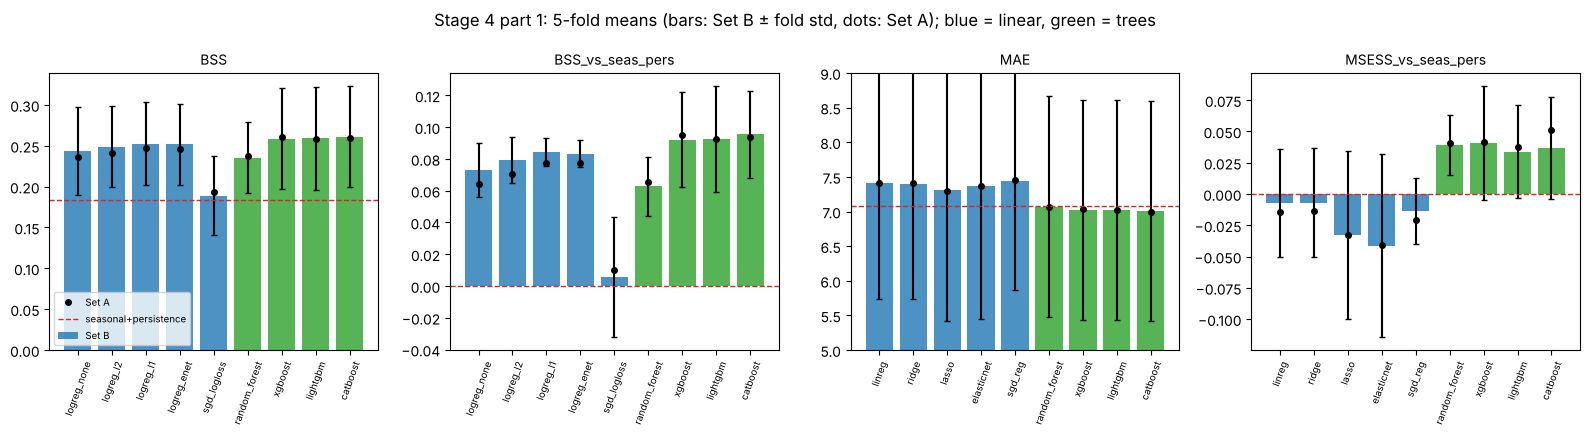

In [13]:
cv = pd.read_csv(E.RESULTS)
panels = [("cls", "BSS"), ("cls", "BSS_vs_seas_pers"), ("reg", "MAE"), ("reg", "MSESS_vs_seas_pers")]
fig, axes = plt.subplots(1, 4, figsize=(16, 4.4))
for ax, (task, met) in zip(axes, panels):
    models = [m for m in (ALL_CLS if task == "cls" else ALL_REG) if not m.startswith("baseline")]
    s = E.summarise(cv[(cv.task == task) & cv.model.isin(models)], [met]).set_index(["model", "feature_set"])
    xb = [s.loc[(m, "B"), "mean"] for m in models]; eb = [s.loc[(m, "B"), "fold_std"] for m in models]
    ax.bar(range(len(models)), xb, yerr=eb, capsize=2, color=["tab:blue"] * 5 + ["tab:green"] * 4, alpha=0.8, label="Set B")
    ax.plot(range(len(models)), [s.loc[(m, "A"), "mean"] for m in models], "ko", ms=4, label="Set A")
    ref = cv[(cv.model == "baseline:seasonal+persistence") & (cv.task == task) & (cv.metric == met)]["value"].mean()
    ax.axhline(ref, color="tab:red", ls="--", lw=1, label="seasonal+persistence")
    ax.set_xticks(range(len(models)), models, rotation=70, fontsize=7); ax.set_title(met, fontsize=10)
    if met == "MAE": ax.set_ylim(5, 9)
axes[0].legend(fontsize=7)
fig.suptitle("Stage 4 part 1: 5-fold means (bars: Set B ± fold std, dots: Set A); blue = linear, green = trees")
fig.tight_layout(); save(fig, "04_part1_model_comparison.png"); plt.show()

**Interpretation:** the figure summarises part 1: all well-converged classifiers sit clearly above the seasonal + persistence
line (left two panels), with the boosters slightly ahead; for regression (right two panels) only the trees cross the reference,
and the MAE error bars (fold std ≈ 1.6 mm) dwarf the differences. Dots (Set A) lie on top of the bars (Set B) almost everywhere.

**Decision:** figure for the results section (`04_part1_model_comparison.png`).

**Paper note:** *Figure X compares cross-validated skill of all classical models with the seasonal-persistence reference.*

### Step 15 — Paired fold-by-fold differences

**WHAT:** for selected pairs, the difference in the headline metric **within each fold** (model − reference), and in how
many of the 5 folds the model is better.

**WHY:** the fold std (≈ 0.05 BSS, ≈ 1.6 mm MAE) is dominated by *how hard each period is*, which affects all models
alike. Comparing two models on the **same** fold removes that shared component — the paired view is the honest way to ask
"is model X consistently better than Y?". (A formal paired bootstrap follows with the final candidates.)

**Look for:** "better in 5/5" (consistent) vs mixed signs (no reliable difference).

In [ ]:
cv = pd.read_csv(E.RESULTS)
def per_fold(model, fset, task, metric):
    s = cv[(cv.model == model) & (cv.feature_set == fset) & (cv.task == task) & (cv.metric == metric)]
    return s.groupby("fold")["value"].mean()

SP = ("baseline:seasonal+persistence", "-")
pairs = [("cls", "BSS", ("catboost", "B"), SP), ("cls", "BSS", ("logreg_l1", "B"), SP),
         ("cls", "BSS", ("random_forest", "B"), SP), ("cls", "BSS", ("catboost", "B"), ("logreg_l1", "B")),
         ("cls", "BSS", ("logreg_l1", "B"), ("logreg_l1", "A")), ("cls", "BSS", ("lightgbm", "B"), ("lightgbm", "A")),
         ("reg", "MAE", ("catboost", "A"), SP), ("reg", "MAE", ("lightgbm", "B"), SP), ("reg", "MAE", ("ridge", "B"), SP),
         ("reg", "MAE", ("catboost", "A"), ("ridge", "B")), ("reg", "MAE", ("catboost", "B"), ("catboost", "A"))]
rows = []
for task, met, (m1, f1), (m2, f2) in pairs:
    d = per_fold(m1, f1, task, met) - per_fold(m2, f2, task, met)
    better = d < 0 if met == "MAE" else d > 0
    rows.append({"comparison": f"{m1} ({f1}) - {m2} ({f2})", "metric": met,
                 **{f"fold {k}": round(v, 3) for k, v in d.items()},
                 "mean diff": round(d.mean(), 3), "better in": f"{int(better.sum())}/5"})
paired = pd.DataFrame(rows)
paired.to_csv(TAB / "04_part1_paired_fold_differences.csv", index=False)
paired

,comparison,metric,fold 1,fold 2,fold 3,fold 4,fold 5,mean diff,better in
0,catboost (B) - baseline:seasonal+persistence (-),BSS,0.048,0.071,0.084,0.081,0.105,0.078,5/5
1,logreg_l1 (B) - baseline:seasonal+persistence (-),BSS,0.060,0.066,0.083,0.062,0.075,0.069,5/5
2,random_forest (B) - baseline:seasonal+persiste...,BSS,0.040,0.055,0.077,0.029,0.058,0.052,5/5
3,catboost (B) - logreg_l1 (B),BSS,-0.012,0.005,0.000,0.019,0.030,0.009,4/5
4,logreg_l1 (B) - logreg_l1 (A),BSS,0.003,0.016,0.008,0.001,0.001,0.006,5/5
5,lightgbm (B) - lightgbm (A),BSS,-0.006,0.008,0.019,-0.004,-0.013,0.001,2/5
6,catboost (A) - baseline:seasonal+persistence (-),MAE,-0.293,-0.069,0.125,0.015,-0.176,-0.080,3/5
7,lightgbm (B) - baseline:seasonal+persistence (-),MAE,-0.213,-0.073,0.122,0.104,-0.233,-0.059,3/5
8,ridge (B) - baseline:seasonal+persistence (-),MAE,0.254,0.418,0.339,0.266,0.340,0.323,0/5
9,catboost (A) - ridge (B),MAE,-0.547,-0.487,-0.214,-0.251,-0.516,-0.403,5/5


**Interpretation:**
- **Every good classifier beats seasonal + persistence in 5 of 5 folds** (CatBoost +0.05 to +0.10 BSS; logreg_l1 +0.06 to +0.08):
  this gain is robust.
- **CatBoost vs logreg_l1:** −0.012, +0.005, 0.000 in folds 1–3, **+0.019, +0.030 in folds 4–5** (the table counts 4/5 because fold 3 is +0.0004 — effectively a tie). Before 2014 the booster is no
  better than a linear model; its advantage appears only in the post-2016 regime. Possible reasons: trees adapt better to the
  shifted moisture/rain levels, or they exploit regime-specific artefacts. This must be re-checked with the IMERG target
  (Stage 6) before it is claimed as "non-linear skill".
- **Regression vs seasonal + persistence:** CatBoost (A) MAE differences −0.29, −0.07, +0.13, +0.02, −0.18 mm → better in only
  3/5 folds, mean −0.08 mm: **no reliable MAE improvement**. (Its RMSE/MSESS gain is more consistent.)
- Ridge is worse than the reference in 5/5 folds; CatBoost beats Ridge in 5/5 folds (by 0.2–0.55 mm).
- Set B vs A: mixed signs for the boosters (2/5) — no evidence that the extended set helps trees.

**Decision:** report paired differences for all headline claims; treat the booster-vs-linear classification gain and the
booster-vs-reference MAE gain as **not yet established**.

**Paper note:** *In paired fold-wise comparisons, all regularised and tree-based classifiers outperformed the
seasonal-persistence reference in every fold, but the advantage of gradient boosting over logistic regression was confined to
the post-2016 folds and the MAE improvement over the reference was not consistent.*

## Stage 4 part 1 — summary (stop for review before Prompts 4.4–4.6)

| question | answer |
|---|---|
| Runner correct? | yes — 6 runner tests + dummy = majority baseline exactly; threshold & early stopping on the last 3 training years only |
| Best classifier | boosters, BSS ≈ 0.26 (vs 0.18 seasonal + persistence; +0.05–0.10 in every fold); `logreg_l1` 0.25 |
| Non-linear advantage (cls)? | small (+0.008 BSS), only in folds 4–5 → not yet established |
| Best regression | boosters, MAE ≈ 7.00 (vs 7.08); better MSESS/RMSE, but MAE better in only 3/5 folds |
| Linear regression | does not beat the reference (zero-inflated, heavy-tailed target) |
| Set A vs B | no meaningful difference |
| Seeds | negligible effect (trees), none for converged convex models; SGD unstable with defaults |
| Rule 11 | 0 hits / 144 configurations |

**Suggestions for part 2 (your call):** (1) regression with a target that matches the data: `y_reg_log` with smearing correction,
Tweedie/Poisson loss (native in LightGBM/XGBoost/CatBoost — to be checked for the installed versions), or a two-part (hurdle) model
P(rain) × E[amount | rain]; (2) paired block-bootstrap tests for the final candidates; (3) the IMERG check of the post-2016 gains
remains essential.

Outputs: `src/experiment.py`, `src/models.py`, `tests/test_experiment.py`, `reports/tables/cv_results.csv`,
`reports/tables/04_*.csv`, `reports/figures/04_*.png`, `models/oof/` (134 files).